In [13]:
# Import essential libraries for model building, training, and evaluation

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_addons as tfa
import sklearn

In [17]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from sklearn.metrics import *
from functools import partial
import matplotlib.pyplot as plt
import seaborn as sns
from keras.models import Sequential, load_model

In [18]:
import os 
import numpy as np
import cv2
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import KFold
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D

In [19]:
## Load and resize images from given paths, assigning the specified target label to each

def loadImages(path,urls, target):
  images = []
  labels = []
  for i in range(len(urls)):
    img_path = path + "/" + urls[i]
    img = cv2.imread(img_path)
    img = cv2.resize(img, (224, 224))
    images.append(img)
    labels.append(target)
  images = np.asarray(images)
  return images, labels

In [20]:
num_classes = 2
input_shape = (224, 224, 3)

In [21]:
normal_path = r"C:\Users\ASUS\Desktop\Kunal_CV_Project\Data\Normal"
normal_urls = os.listdir(normal_path)
normalImages, normalTargets = loadImages(normal_path,normal_urls, 0)

In [22]:
len(normalTargets), len(normalImages)

(2494, 2494)

In [23]:
normalImages.shape

(2494, 224, 224, 3)

In [24]:
ab_path =r"C:\Users\ASUS\Desktop\Kunal_CV_Project\Data\OSCC"
ab_urls = os.listdir(ab_path)
abImages, abTargets = loadImages(ab_path,ab_urls, 1)

In [25]:
abImages.shape

(2698, 224, 224, 3)

In [26]:
data = np.r_[normalImages, abImages] #concatenation

In [27]:
data.shape

(5192, 224, 224, 3)

In [28]:
targets = np.r_[normalTargets, abTargets]

In [29]:
targets.shape

(5192,)

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
x_train, x_test, y_train, y_test = train_test_split(data, targets, test_size=0.20)
print(f"x_train shape: {x_train.shape} - y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape} - y_test shape: {y_test.shape}")

x_train shape: (4153, 224, 224, 3) - y_train shape: (4153,)
x_test shape: (1039, 224, 224, 3) - y_test shape: (1039,)


In [32]:
learning_rate = 0.001  # Learning rate for the optimizer
weight_decay = 0.0001  # Weight decay (L2 regularization) to prevent overfitting
batch_size = 16        # Number of samples per training batch
num_epochs = 100       # Total number of training epochs
image_size = 224       # Input images will be resized to 224x224 pixels
patch_size = 14        # Size of each patch extracted from the input image (14x14)
num_patches = (image_size // patch_size) ** 2        # Total number of patches per image
projection_dim = 64    # Dimension to project each patch for embedding
num_heads = 4           # Number of attention heads in the multi-head self-attention layer
transformer_units = [    
    projection_dim * 2,     # First dense layer unit size in transformer block
    projection_dim,         # Second dense layer unit size in transformer block
]  
transformer_layers = 8      # Number of stacked transformer encoder layers
mlp_head_units = [2048, 1024]  # Number of units in each dense layer of the MLP head (final classifier)

In [33]:
# Define a sequential data augmentation pipeline
data_augmentation = keras.Sequential(
    [
        layers.Normalization(),                          # Normalize input images (mean=0, std=1)
        layers.Resizing(image_size, image_size),         # Resize images to target size (224x224)
        layers.RandomFlip("horizontal"),                 # Randomly flip images horizontally
        layers.RandomRotation(factor=0.02),              # Randomly rotate images by ±2% of 360°
        layers.RandomZoom(height_factor=0.2, width_factor=0.2),  # Randomly zoom images by up to 20%
    ],
    name="data_augmentation",
)

# Compute and set the mean and variance of the training set for normalization
data_augmentation.layers[0].adapt(x_train)

In [34]:
def mlp(x, hidden_units, dropout_rate):  # Implement a Multilayer Perceptron (MLP) block with GELU activation and dropout
    for units in hidden_units:
        x = layers.Dense(units, activation=tf.nn.gelu)(x)  # Fully connected layer with GELU activation
        x = layers.Dropout(dropout_rate)(x)                # Apply dropout for regularization
    return x  # Return the output of the MLP block

In [35]:
# Custom Keras layer to extract non-overlapping patches from input images
class Patches(layers.Layer):
    def __init__(self, patch_size):
        super(Patches, self).__init__()
        self.patch_size = patch_size  # Size of each square patch

    def call(self, images):
        batch_size = tf.shape(images)[0]  # Get the batch size dynamically

        # Extract non-overlapping patches from images
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],  # Patch size
            strides=[1, self.patch_size, self.patch_size, 1],  # Move in patch-sized steps
            rates=[1, 1, 1, 1],  # Sampling rate (1 = no dilation)
            padding="VALID",  # No padding; only full patches are kept
        )

        patch_dims = patches.shape[-1]  # Number of values per patch
        # Reshape patches to [batch_size, num_patches, patch_dims]
        patches = tf.reshape(patches, [batch_size, -1, patch_dims])
        return patches  # Return extracted patches as flat vectors

Image size: 224 X 224
Patch size: 14 X 14
Patches per image: 256
Elements per patch: 588


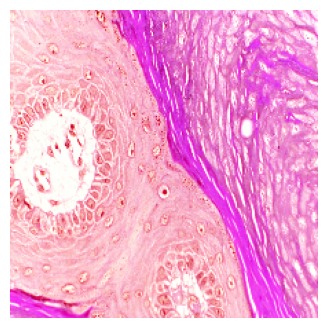

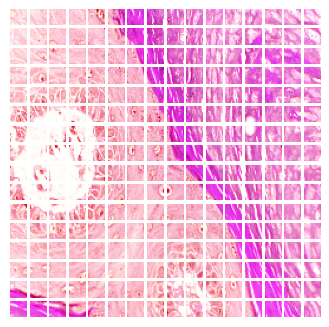

In [36]:
import matplotlib.pyplot as plt

# Select a random image from the training set and display it
plt.figure(figsize=(4, 4))
image = x_train[np.random.choice(range(x_train.shape[0]))]  # Randomly select one image from the training set
plt.imshow(image.astype("uint8"))  # Display the image
plt.axis("off")  # Turn off axis for clean visualization

# Resize the selected image to the required input size for the model
resized_image = tf.image.resize(
    tf.convert_to_tensor([image]), size=(image_size, image_size)
)

# Extract patches from the resized image using the custom Patches layer
patches = Patches(patch_size)(resized_image)

# Print patching details
print(f"Image size: {image_size} X {image_size}")
print(f"Patch size: {patch_size} X {patch_size}")
print(f"Patches per image: {patches.shape[1]}")      # Total number of patches
print(f"Elements per patch: {patches.shape[-1]}")    # Number of elements in each patch

# Plot all the extracted patches as small image tiles
n = int(np.sqrt(patches.shape[1]))  # Assuming patches are arranged in a square grid
plt.figure(figsize=(4, 4))
for i, patch in enumerate(patches[0]):
    ax = plt.subplot(n, n, i + 1)  # Create a grid of subplots
    patch_img = tf.reshape(patch, (patch_size, patch_size, 3))  # Reshape flat patch back to image patch
    plt.imshow(patch_img.numpy().astype("uint8"))  # Display each patch
    plt.axis("off")  # Hide axes for clarity

In [37]:
# Custom Keras layer to encode image patches by projecting them and adding positional embeddings
class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super(PatchEncoder, self).__init__()
        self.num_patches = num_patches  # Total number of patches per image
        self.projection = layers.Dense(units=projection_dim)  # Linear projection layer to map each patch to a vector of projection_dim size
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim  # Learnable positional embedding for each patch
        )

    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)  # Generate a sequence of patch indices
        encoded = self.projection(patch) + self.position_embedding(positions)  # Add positional encoding to patch embeddings
        return encoded  # Return the encoded patches with positional context

In [38]:
# Define the Vision Transformer (ViT) classifier model

inputs = layers.Input(shape=input_shape)  # Input layer with specified image shape

# Apply data augmentation (normalization, resizing, flipping, rotation, zoom)
augmented = data_augmentation(inputs)

# Divide augmented images into non-overlapping patches
patches = Patches(patch_size)(augmented)

# Encode patches with a learnable linear projection and positional embeddings
encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

# Apply multiple stacked transformer encoder blocks
for _ in range(transformer_layers):
    # Layer normalization before self-attention
    x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)

    # Multi-head self-attention: models global relationships between patches
    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=projection_dim, dropout=0.1
    )(x1, x1)

    # First residual (skip) connection
    x2 = layers.Add()([attention_output, encoded_patches])

    # Layer normalization before MLP block
    x3 = layers.LayerNormalization(epsilon=1e-6)(x2)

    # Feed-forward network (MLP block) with GELU activation and dropout
    x3 = mlp(x3, hidden_units=transformer_units, dropout_rate=0.1)

    # Second residual (skip) connection
    encoded_patches = layers.Add()([x3, x2])

# Final layer normalization before classification head
representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)

# Flatten the sequence of patch embeddings
representation = layers.Flatten()(representation)

# Apply dropout for regularization
representation = layers.Dropout(0.5)(representation)

# Final MLP classification head
features = mlp(representation, hidden_units=mlp_head_units, dropout_rate=0.5)

# Output classification layer (logits for each class)
logits = layers.Dense(num_classes)(features)

# Define the complete Keras model
model = keras.Model(inputs=inputs, outputs=logits)

In [39]:
# Display a summary of the model architecture, including each layer's name, output shape, and number of parameters
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 data_augmentation (Sequential)  (None, 224, 224, 3)  7          ['input_1[0][0]']                
                                                                                                  
 patches_1 (Patches)            (None, None, 588)    0           ['data_augmentation[0][0]']      
                                                                                                  
 patch_encoder (PatchEncoder)   (None, 256, 64)      54080       ['patches_1[0][0]']          

                                                                                                  
 multi_head_attention_3 (MultiH  (None, 256, 64)     66368       ['layer_normalization_6[0][0]',  
 eadAttention)                                                    'layer_normalization_6[0][0]']  
                                                                                                  
 add_6 (Add)                    (None, 256, 64)      0           ['multi_head_attention_3[0][0]', 
                                                                  'add_5[0][0]']                  
                                                                                                  
 layer_normalization_7 (LayerNo  (None, 256, 64)     128         ['add_6[0][0]']                  
 rmalization)                                                                                     
                                                                                                  
 dense_7 (

 dense_14 (Dense)               (None, 256, 64)      8256        ['dropout_12[0][0]']             
                                                                                                  
 dropout_13 (Dropout)           (None, 256, 64)      0           ['dense_14[0][0]']               
                                                                                                  
 add_13 (Add)                   (None, 256, 64)      0           ['dropout_13[0][0]',             
                                                                  'add_12[0][0]']                 
                                                                                                  
 layer_normalization_14 (LayerN  (None, 256, 64)     128         ['add_13[0][0]']                 
 ormalization)                                                                                    
                                                                                                  
 multi_hea

Epoch 1/100
260/260 [==============================] - 32s 87ms/step - loss: 2.7490 - accuracy: 0.6039 - top-5-accuracy: 1.0000 - val_loss: 0.6174 - val_accuracy: 0.6458 - val_top-5-accuracy: 1.0000
Epoch 2/100
260/260 [==============================] - 22s 83ms/step - loss: 0.6405 - accuracy: 0.6694 - top-5-accuracy: 1.0000 - val_loss: 0.5323 - val_accuracy: 0.7180 - val_top-5-accuracy: 1.0000
Epoch 3/100
260/260 [==============================] - 22s 84ms/step - loss: 0.5780 - accuracy: 0.7074 - top-5-accuracy: 1.0000 - val_loss: 0.5157 - val_accuracy: 0.7584 - val_top-5-accuracy: 1.0000
Epoch 4/100
260/260 [==============================] - 22s 84ms/step - loss: 0.5486 - accuracy: 0.7190 - top-5-accuracy: 1.0000 - val_loss: 0.5264 - val_accuracy: 0.6968 - val_top-5-accuracy: 1.0000
Epoch 5/100
260/260 [==============================] - 23s 87ms/step - loss: 0.5496 - accuracy: 0.7255 - top-5-accuracy: 1.0000 - val_loss: 0.5478 - val_accuracy: 0.7623 - val_top-5-accuracy: 1.0000
Epoch

Epoch 42/100
260/260 [==============================] - 21s 82ms/step - loss: 0.1710 - accuracy: 0.9297 - top-5-accuracy: 1.0000 - val_loss: 0.1802 - val_accuracy: 0.9307 - val_top-5-accuracy: 1.0000
Epoch 43/100
260/260 [==============================] - 22s 84ms/step - loss: 0.1709 - accuracy: 0.9345 - top-5-accuracy: 1.0000 - val_loss: 0.1952 - val_accuracy: 0.9384 - val_top-5-accuracy: 1.0000
Epoch 44/100
260/260 [==============================] - 22s 86ms/step - loss: 0.1872 - accuracy: 0.9285 - top-5-accuracy: 1.0000 - val_loss: 0.2564 - val_accuracy: 0.9066 - val_top-5-accuracy: 1.0000
Epoch 45/100
260/260 [==============================] - 22s 84ms/step - loss: 0.2115 - accuracy: 0.9167 - top-5-accuracy: 1.0000 - val_loss: 0.2062 - val_accuracy: 0.9124 - val_top-5-accuracy: 1.0000
Epoch 46/100
260/260 [==============================] - 22s 84ms/step - loss: 0.1841 - accuracy: 0.9246 - top-5-accuracy: 1.0000 - val_loss: 0.1808 - val_accuracy: 0.9259 - val_top-5-accuracy: 1.0000


Epoch 83/100
260/260 [==============================] - 22s 84ms/step - loss: 0.1211 - accuracy: 0.9557 - top-5-accuracy: 1.0000 - val_loss: 0.1833 - val_accuracy: 0.9374 - val_top-5-accuracy: 1.0000
Epoch 84/100
260/260 [==============================] - 22s 85ms/step - loss: 0.1421 - accuracy: 0.9494 - top-5-accuracy: 1.0000 - val_loss: 0.1508 - val_accuracy: 0.9403 - val_top-5-accuracy: 1.0000
Epoch 85/100
260/260 [==============================] - 22s 83ms/step - loss: 0.1408 - accuracy: 0.9492 - top-5-accuracy: 1.0000 - val_loss: 0.1255 - val_accuracy: 0.9538 - val_top-5-accuracy: 1.0000
Epoch 86/100
260/260 [==============================] - 21s 82ms/step - loss: 0.1129 - accuracy: 0.9576 - top-5-accuracy: 1.0000 - val_loss: 0.1971 - val_accuracy: 0.9365 - val_top-5-accuracy: 1.0000
Epoch 87/100
260/260 [==============================] - 22s 83ms/step - loss: 0.1101 - accuracy: 0.9564 - top-5-accuracy: 1.0000 - val_loss: 0.1769 - val_accuracy: 0.9403 - val_top-5-accuracy: 1.0000


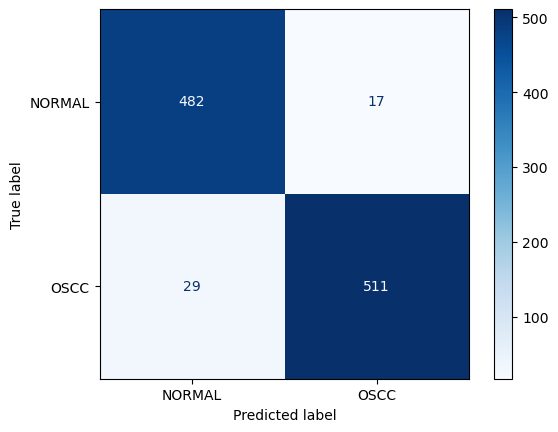

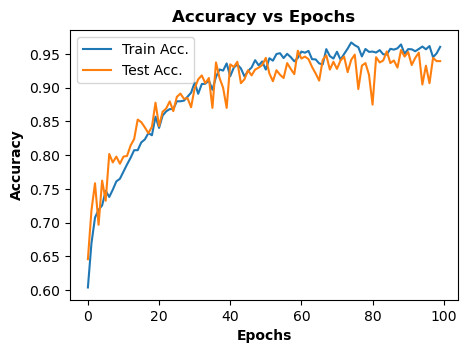

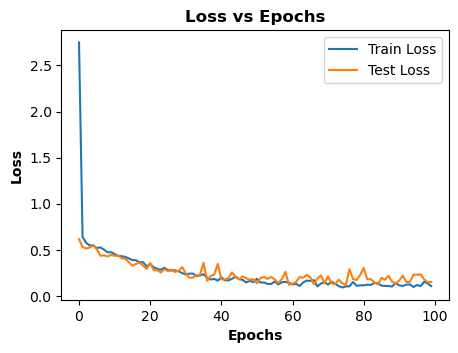

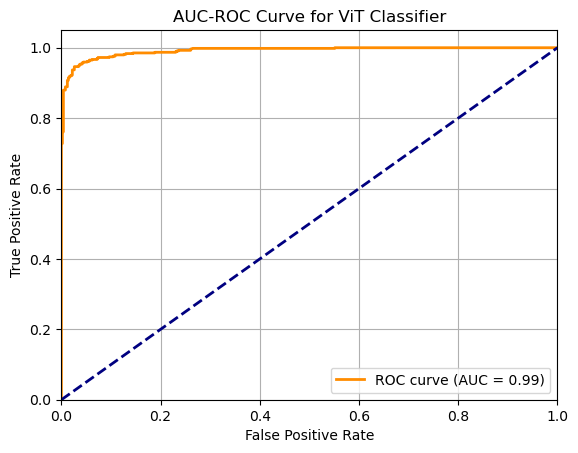

In [40]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_addons as tfa
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize

# Split the dataset into training and testing sets (80:20 split)
x_train, x_test, y_train, y_test = train_test_split(data, targets, test_size=0.2, stratify=targets)

# Compile the model
optimizer = tfa.optimizers.AdamW(learning_rate=learning_rate, weight_decay=weight_decay)
model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(5, name="top-5-accuracy"),
    ],
)

# Define the ModelCheckpoint callback
checkpoint_filepath = 'Run2_bestw.h5'
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True
)

# Record start time
start_time = time.time()

# Train the model
history = model.fit(
    x_train, y_train,
    batch_size=16,
    epochs=100,
    validation_data=(x_test, y_test),
    callbacks=[model_checkpoint_callback]
)

# Record end time
end_time = time.time()

# Print time info
print("Start Time:", time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(start_time)))
print("End Time:", time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(end_time)))
print("Total Time Taken: {:.2f} seconds".format(end_time - start_time))

# Load the best weights
model.load_weights(checkpoint_filepath)

# Evaluate the model
scores = model.evaluate(x_test, y_test, verbose=0)
print(f'Final Test Loss: {scores[0]:.4f}')
print(f'Final Test Accuracy: {scores[1]*100:.2f}%')

# Predict and evaluate
y_pred_logits = model.predict(x_test, batch_size=16, verbose=1)
y_pred_prob = tf.nn.softmax(y_pred_logits, axis=1).numpy()
y_pred_bool = np.argmax(y_pred_prob, axis=1)

# Classification metrics
print(classification_report(y_test, y_pred_bool))
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred_bool), display_labels=['NORMAL', 'OSCC'])
disp.plot(cmap='Blues')
plt.show()

# Accuracy vs Epochs
plt.figure(figsize=(5, 3.5))
plt.plot(history.history['accuracy'], label='Train Acc.')
plt.plot(history.history['val_accuracy'], label='Test Acc.')
plt.title('Accuracy vs Epochs', fontweight='bold')
plt.xlabel('Epochs', fontweight='bold')
plt.ylabel('Accuracy', fontweight='bold')
plt.legend()
plt.show()

# Loss vs Epochs
plt.figure(figsize=(5, 3.5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.title('Loss vs Epochs', fontweight='bold')
plt.xlabel('Epochs', fontweight='bold')
plt.ylabel('Loss', fontweight='bold')
plt.legend()
plt.show()

# ROC-AUC Curve
y_test_bin = label_binarize(y_test, classes=[0, 1])
fpr, tpr, _ = roc_curve(y_test_bin, y_pred_prob[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC-ROC Curve for ViT Classifier')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()